# JAX ADE 逆向设计 — 2D TMz 透射最大化

本 notebook 是 `examples/inverse_design_2d.py` 的 notebook 版本，适合在已安装
`fdtdz_jax` 与 `jax` 的 Jupyter 内核里直接运行。

目标：用 scipy L-BFGS-B + JAX 端到端梯度，优化设计区密度，最大化透射探针能量。


In [1]:
import jax
jax.config.update("jax_enable_x64", True)

import jax.numpy as jnp
import numpy as np

from fdtdz_jax import (
    DesignParameters,
    DesignRegion,
    InverseDesignProblem,
    ProbeTrace,
    minimize_lbfgsb,
)
from fdtdz_jax.materials import Lossless
from fdtdz_jax.metasurface_2d import gaussian_sine_pulse, huygens_current_waveforms
from fdtdz_jax.yee_ade_2d import prepare_material_grid_2d, prepare_y_cpml


## 1. 网格、CPML 与入射源

背景为无损介质 `eps = 1`；y 方向加 CPML 吸收边界；用 Huygens 线源沿 +y 单向入射。
设计区必须落在 CPML 之外。


In [2]:
nx, ny = 32, 64
dt, dx, dy = 0.5, 1.0, 1.0
eps_min, eps_max = 1.0, 9.0
cpml_width = 8

cpml = prepare_y_cpml((nx, ny), cpml_width, dt, dy, dtype=np.float64)
grid = prepare_material_grid_2d(
    [Lossless(eps_min)],
    np.zeros((nx, ny), dtype=int),
    dt,
    dx,
    dy,
    dtype=np.float64,
    y_cpml=cpml,
)

num_steps = 240
waveform = gaussian_sine_pulse(
    num_steps, dt, center_time=20.0, width=10.0, frequency=0.3,
    dtype=np.float64,
)
electric, magnetic = huygens_current_waveforms(
    waveform, direction=1, wave_impedance=1.0, dtype=np.float64
)


## 2. 设计区参数化

设计变量是 `[0, 1]` 的密度 `weights`，依次经过 conic 滤波、tanh 投影、SIMP 插值，
映射到介电常数。`medium1` 对应密度 0，`medium2` 对应密度 1。


In [3]:
grid_size = (12, 8)
params = DesignParameters(
    grid_size=grid_size,
    medium1=eps_min,
    medium2=eps_max,
    weights=np.full(grid_size[0] * grid_size[1], 0.5),
    beta=2.0,          # tanh 投影强度，0 表示不投影
    p=3.0,             # SIMP 指数
    filter_type="conic",
    radius=1.5,
)
region = DesignRegion(
    params, x0=10, x1=10 + grid_size[0], y0=28, y1=28 + grid_size[1]
)


## 3. 问题与目标

`InverseDesignProblem` 对齐 Meep 的 `OptimizationProblem`。目标函数是透射探针
时间序列能量的负值——最小化它即最大化透射。


In [4]:
problem = InverseDesignProblem(
    grid,
    region,
    electric,
    magnetic,
    np.ones(nx, dtype=np.float64),
    source_y=14,
    reflection_probe_y=18,
    transmission_probe_y=46,
    objective_arguments=[ProbeTrace(probe="transmission")],
    objective_functions=[lambda t: -jnp.mean(jnp.square(t))],
)


## 4. 优化

用 scipy L-BFGS-B，梯度由 `jax.value_and_grad` 自动求取；`callback` 记录每次
迭代的目标值。


In [5]:
rho0 = np.full(grid_size[0] * grid_size[1], 0.5)
f, _ = problem.get_fdf_funcs()
history = [float(np.asarray(f(rho0)))]

def record(xk):
    history.append(float(np.asarray(f(xk))))

result = minimize_lbfgsb(problem, rho0, maxiter=30, callback=record)

print(f"initial objective: {history[0]:.6f}")
print(f"final   objective: {history[-1]:.6f}")
print(f"iterations: {result.nit}, converged: {result.success}")


initial objective: -0.083622
final   objective: -0.125901
iterations: 30, converged: False


## 5. 结果可视化

左图是优化后的密度（`DesignRegion` 内），右图是目标值随迭代的收敛曲线。


inverse_design_2d.ipynb:cell-11:17: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


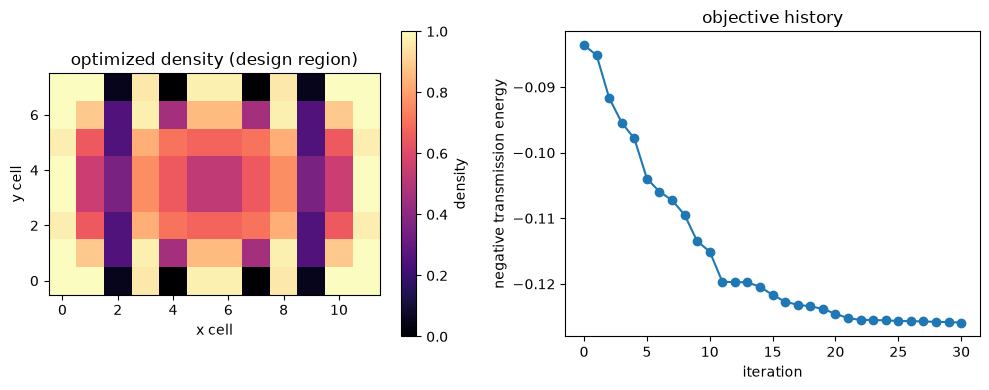

In [6]:
import matplotlib.pyplot as plt

density = problem.design_regions[0].design_parameters.weights.reshape(grid_size)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
im = axes[0].imshow(density.T, origin="lower", cmap="magma", vmin=0.0, vmax=1.0)
axes[0].set_title("optimized density (design region)")
axes[0].set_xlabel("x cell")
axes[0].set_ylabel("y cell")
fig.colorbar(im, ax=axes[0], label="density")

axes[1].plot(history, marker="o")
axes[1].set_title("objective history")
axes[1].set_xlabel("iteration")
axes[1].set_ylabel("negative transmission energy")
fig.tight_layout()
plt.show()
